# Predictive Modelling - Road Accidents

This notebook investigates whether historical municipality-level information
can be used to explain and predict road accident volumes.

Previous-year accident data is first used to predict the following year's
number of accidents.

A time-based evaluation uses data from 2021–2023 for training and 2024 as an
unseen test year.

In [51]:
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.api as sm

sns.set_theme()

In [52]:
cleaned_path = Path(
    "data/cleaned/istat_traffic_2020_2024_cleaned.csv"
)

df = pd.read_csv(
    cleaned_path,
    keep_default_na=False,
    na_values=[""]
)

df.shape

(39507, 13)

In [53]:
df.head()

,REF_AREA,municipality,region_code,province_code,province_abbr,area_km2,population,TIME_PERIOD,accidents,injured,killed,accidents_per_100k,accidents_per_km2
0,1001,Agliè,1,201,TO,13.1462,2545,2020,4,4,0,157.170923,0.304270
1,1002,Airasca,1,201,TO,15.7393,3633,2020,8,14,0,220.203688,0.508282
2,1003,Ala di Stura,1,201,TO,46.3315,459,2020,0,0,0,0.000000,0.000000
3,1004,Albiano d'Ivrea,1,201,TO,11.7314,1638,2020,3,3,0,183.150183,0.255724
4,1006,Almese,1,201,TO,17.8756,6355,2020,6,8,0,94.413847,0.335653


In [54]:
df["TIME_PERIOD"].value_counts().sort_index()

TIME_PERIOD
2020    7903
2021    7904
2022    7904
2023    7900
2024    7896
Name: count, dtype: int64

## 1. Simple Linear Regression

The first regression model investigates whether the number of road accidents
in the previous year can explain the number of accidents in the following year.

In [55]:
df.duplicated(subset=["REF_AREA", "TIME_PERIOD"]).sum()

np.int64(0)

In [56]:
previous_year = df[
    [
        "REF_AREA",
        "TIME_PERIOD",
        "accidents"
    ]
].copy()

previous_year["TIME_PERIOD"] = (
    previous_year["TIME_PERIOD"] + 1
)

previous_year = previous_year.rename(
    columns={
        "accidents": "previous_accidents"
    }
)

In [57]:
df_reg = df.merge(
    previous_year,
    on=["REF_AREA", "TIME_PERIOD"],
    how="left",
    validate="one_to_one"
)

In [58]:
df_reg[
    [
        "municipality",
        "TIME_PERIOD",
        "previous_accidents",
        "accidents"
    ]
].head(15)

,municipality,TIME_PERIOD,previous_accidents,accidents
0,Agliè,2020,NaN,4
1,Airasca,2020,NaN,8
2,Ala di Stura,2020,NaN,0
3,Albiano d'Ivrea,2020,NaN,3
4,Almese,2020,NaN,6
5,Alpette,2020,NaN,1
6,Alpignano,2020,NaN,18
7,Andezeno,2020,NaN,1
8,Andrate,2020,NaN,0
9,Angrogna,2020,NaN,0


In [59]:
df_reg[pd.isna(df_reg.previous_accidents)][[
        "municipality",
        "TIME_PERIOD",
        "previous_accidents",
        "accidents"
    ]
].head()

,municipality,TIME_PERIOD,previous_accidents,accidents
0,Agliè,2020,NaN,4
1,Airasca,2020,NaN,8
2,Ala di Stura,2020,NaN,0
3,Albiano d'Ivrea,2020,NaN,3
4,Almese,2020,NaN,6


In [60]:
df_reg = df_reg[~pd.isna(df_reg.previous_accidents)]
df_reg.shape

(31595, 14)

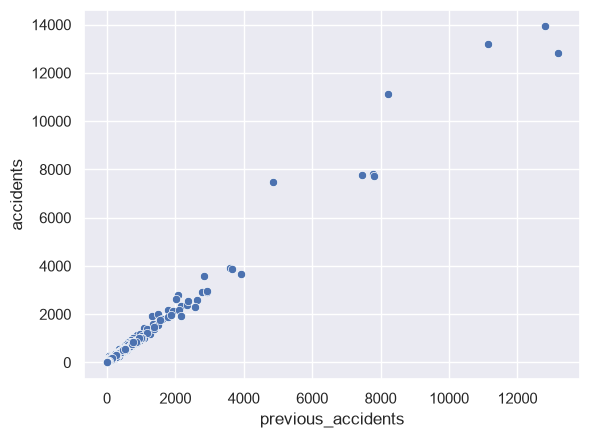

In [61]:
sns.scatterplot(
    x="previous_accidents",
    y="accidents",
    data=df_reg
)
plt.show()

In [62]:
correl = df_reg.previous_accidents.corr(
    df_reg.accidents
)

print(
    "Correlation coefficient between X and Y:",
    round(correl, 3)
)

Correlation coefficient between X and Y: 0.992


### Correlation Matrix

Before fitting the regression model, correlations between the numerical
variables are examined.

The main relationship of interest is between previous-year accidents and
current-year accidents.

In [63]:
df_reg.corr(numeric_only=True)

,REF_AREA,region_code,province_code,area_km2,population,TIME_PERIOD,accidents,injured,killed,accidents_per_100k,accidents_per_km2,previous_accidents
REF_AREA,1.000000,0.777497,0.379934,0.186116,0.020278,0.000686,0.002714,0.005780,0.023650,-0.108216,-0.026168,0.002309
region_code,0.777497,1.000000,0.395654,0.249057,0.030485,0.000529,0.008815,0.013108,0.040588,-0.118542,-0.064192,0.008549
province_code,0.379934,0.395654,1.000000,0.065171,0.099478,0.000472,0.068355,0.072028,0.075966,-0.047488,0.161534,0.067733
area_km2,0.186116,0.249057,0.065171,1.000000,0.379875,0.000354,0.345749,0.354248,0.435947,0.083716,-0.029517,0.342163
population,0.020278,0.030485,0.099478,0.379875,1.000000,-0.000028,0.972942,0.976888,0.909377,0.095800,0.439357,0.961840
TIME_PERIOD,0.000686,0.000529,0.000472,0.000354,-0.000028,1.000000,0.004844,0.005242,0.002526,0.036916,0.020296,0.012897
accidents,0.002714,0.008815,0.068355,0.345749,0.972942,0.004844,1.000000,0.999020,0.889520,0.110147,0.428955,0.991925
injured,0.005780,0.013108,0.072028,0.354248,0.976888,0.005242,0.999020,1.000000,0.893184,0.113804,0.432157,0.990945
killed,0.023650,0.040588,0.075966,0.435947,0.909377,0.002526,0.889520,0.893184,1.000000,0.134677,0.320122,0.883131
accidents_per_100k,-0.108216,-0.118542,-0.047488,0.083716,0.095800,0.036916,0.110147,0.113804,0.134677,1.000000,0.261367,0.105784


### Simple Linear Regression Model

A simple linear regression model is used to estimate the relationship between
previous-year accidents and current-year accidents.

- Predictor (X): previous-year accidents
- Response (Y): current-year accidents

In [64]:
Y = df_reg["accidents"]

X = df_reg["previous_accidents"]

X = sm.add_constant(data=X)

model = sm.OLS(endog=Y, exog=X)

results = model.fit()

In [65]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              accidents   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.984
Method:                 Least Squares   F-statistic:                 1.933e+06
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:52:07   Log-Likelihood:            -1.4571e+05
No. Observations:               31595   AIC:                         2.914e+05
Df Residuals:                   31593   BIC:                         2.914e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.0243      0.138      0.177      0.860      -0.246       0.295
previous_accidents     1.0901      0.001   1390.199      0.000       1.089       1.092
==============================================================================
Omnibus:                    90000.821   Durbin-Watson:                   1.986
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      28790453682.937
Skew:                          37.224   Prob(JB):                         0.00
Kurtosis:                    4678.905   Cond. No.                         177.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

 Regression Results

The coefficient for previous-year accidents is approximately 1.09 and is
statistically significant (p < 0.05).

This indicates a strong positive relationship between previous-year and
current-year road accidents.

The model has an R-squared of 0.984, meaning that approximately 98.4% of the
variation in current-year accidents is explained by previous-year accidents
within this dataset.

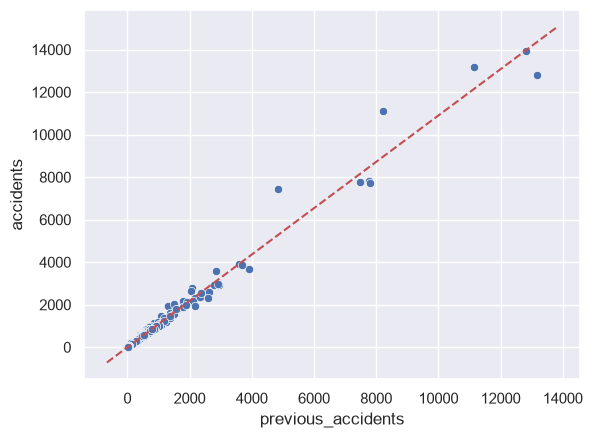

In [66]:
sns.scatterplot(
    x="previous_accidents",
    y="accidents",
    data=df_reg
)

intercept = results.params["const"]
slope = results.params["previous_accidents"]

axes = plt.gca()
x_vals = np.array(axes.get_xlim())
y_vals = intercept + slope * x_vals

plt.plot(x_vals, y_vals, "--", color="r")

plt.show()

### Example Prediction

The fitted model can be used to estimate current-year accidents from the
number of accidents recorded in the previous year.

The example below assumes that a municipality recorded 100 accidents in the
previous year.

In [67]:
results.predict(
    np.array([1, 100])
)

array([109.03389773])

The model predicts approximately 109 current-year accidents for a municipality
that recorded 100 accidents in the previous year.

## 2. Simple Regression - Predictive Evaluation

The simple linear regression model is now evaluated as a predictive model.

Data from 2021–2023 is used for training, while 2024 is kept as an
unseen test year.

The model uses previous-year accidents to predict current-year accidents.

In [68]:
train_df = df_reg[
    df_reg["TIME_PERIOD"].isin([2021, 2022, 2023])
].copy()

test_df = df_reg[
    df_reg["TIME_PERIOD"] == 2024
].copy()

print("Training observations:", train_df.shape[0])
print("Test observations:", test_df.shape[0])

Training observations: 23703
Test observations: 7892


### Training the predictive model

The regression model is fitted using only the 2021–2023 observations.

The 2024 observations are kept completely separate and will be used to
evaluate the model on an unseen test year.

In [69]:
y_train_time = train_df["accidents"]

X_train_time = train_df[
    ["previous_accidents"]
]

X_train_time = sm.add_constant(
    X_train_time
)

time_model = sm.OLS(
    y_train_time,
    X_train_time
)

time_results = time_model.fit()

In [70]:
time_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              accidents   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                 1.143e+06
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:52:07   Log-Likelihood:            -1.1158e+05
No. Observations:               23703   AIC:                         2.232e+05
Df Residuals:                   23701   BIC:                         2.232e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.0669      0.175      0.382      0.703      -0.276       0.410
previous_accidents     1.1069      0.001   1069.343      0.000       1.105       1.109
==============================================================================
Omnibus:                    59212.969   Durbin-Watson:                   1.987
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      14609131325.588
Skew:                          25.994   Prob(JB):                         0.00
Kurtosis:                    3848.710   Cond. No.                         170.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Predicting the unseen 2024 observations

The fitted model is now used to predict accident counts for the 2024 test data.

The model has not used the 2024 observations during training.

In [71]:
y_test_time = test_df["accidents"]

X_test_time = test_df[
    ["previous_accidents"]
]

X_test_time = sm.add_constant(
    X_test_time
)

In [72]:
pred_test_time = time_results.predict(
    X_test_time
)

In [73]:
test_results = test_df[
    [
        "municipality",
        "previous_accidents",
        "accidents"
    ]
].copy()

test_results["predicted_accidents"] = pred_test_time

test_results.head(10)

,municipality,previous_accidents,accidents,predicted_accidents
31611,Agliè,3.0,2,3.387671
31612,Airasca,7.0,5,7.815422
31613,Ala di Stura,1.0,1,1.173796
31614,Albiano d'Ivrea,2.0,4,2.280733
31615,Almese,2.0,2,2.280733
31616,Alpette,1.0,0,1.173796
31617,Alpignano,27.0,20,29.954177
31618,Andezeno,2.0,2,2.280733
31619,Andrate,0.0,1,0.066858
31620,Angrogna,0.0,0,0.066858


In [74]:
def mae(y, pred):
    return round(
        np.mean(
            np.abs(y - pred)
        ),
        2
    )

In [75]:
test_mae = mae(
    y_test_time,
    pred_test_time
)

print(
    "Testing MAE:",
    test_mae
)

Testing MAE: 4.03


I calculate the training MAE to compare the training and test sets and see if there is any potential overfitting.

In [76]:
pred_train_time = time_results.predict(
    X_train_time
)

train_mae = mae(
    y_train_time,
    pred_train_time
)

print(
    "Training MAE:",
    train_mae
)

print(
    "Testing MAE:",
    test_mae
)

Training MAE: 4.28
Testing MAE: 4.03


Naïve benchmark based on the target mean.

In [77]:
print(
    "Naive Training MAE:",
    mae(
        y_train_time,
        np.mean(y_train_time)
    )
)

print(
    "Training MAE:",
    train_mae
)

Naive Training MAE: 27.68
Training MAE: 4.28


In [78]:
print(
    "Naive Testing MAE:",
    mae(
        y_test_time,
        np.mean(y_train_time)
    )
)

print(
    "Testing MAE:",
    test_mae
)

Naive Testing MAE: 28.69
Testing MAE: 4.03


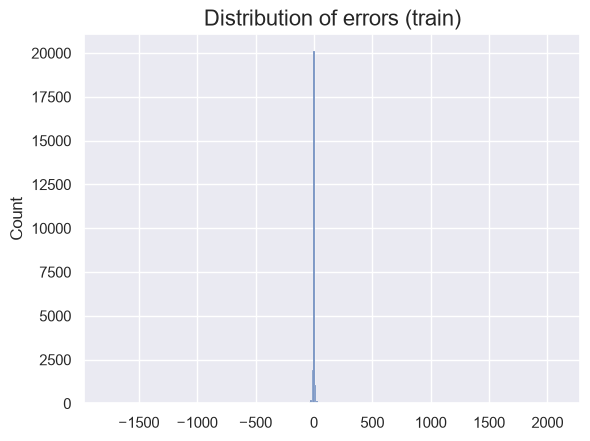

In [79]:
sns.histplot(
    y_train_time - pred_train_time
).set_title(
    "Distribution of errors (train)",
    size=16
)

plt.show()

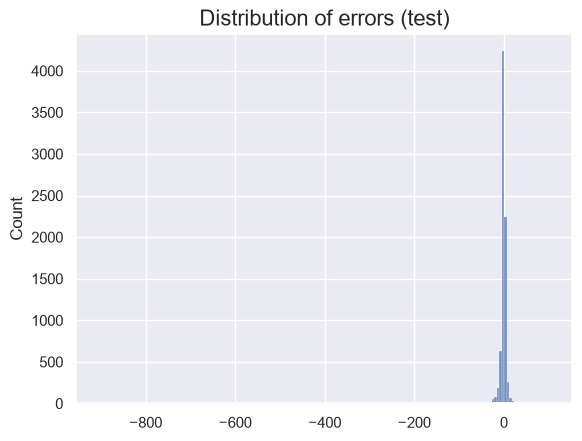

In [80]:
sns.histplot(
    y_test_time - pred_test_time
).set_title(
    "Distribution of errors (test)",
    size=16
)

plt.show()

Error distributions

Most prediction errors are concentrated close to zero.

However, a small number of municipalities show much larger errors, which
stretches the horizontal scale of the distributions.

Training and testing errors show a similar general pattern, while the MAE
values are also close (4.28 for training and 4.03 for testing), suggesting
no clear evidence of overfitting.

### Actual vs Predicted Accidents - 2024

The predicted accident counts are compared with the actual 2024 observations.

Points close to the diagonal line indicate predictions that are close to the
observed values.

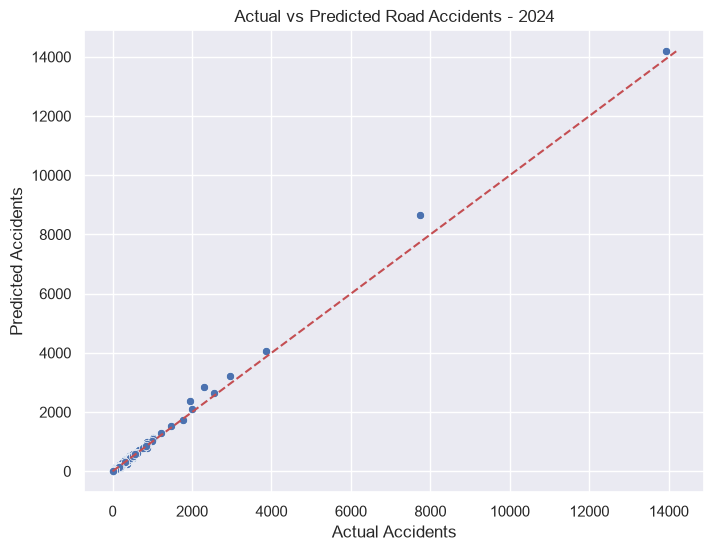

In [81]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test_time,
    y=pred_test_time
)

min_value = min(
    y_test_time.min(),
    pred_test_time.min()
)

max_value = max(
    y_test_time.max(),
    pred_test_time.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "--",
    color="r"
)

plt.title("Actual vs Predicted Road Accidents - 2024")
plt.xlabel("Actual Accidents")
plt.ylabel("Predicted Accidents")

plt.show()

In [82]:
persistence_pred = test_df["previous_accidents"]

persistence_mae = mae(
    y_test_time,
    persistence_pred
)

print(
    "Persistence Baseline MAE:",
    persistence_mae
)

print(
    "Regression Testing MAE:",
    test_mae
)

Persistence Baseline MAE: 3.67
Regression Testing MAE: 4.03


 Simple Regression Conclusion

Previous-year accident counts show a strong positive relationship with
current-year accidents.

The regression model achieved similar performance on the training and test
data, with a Training MAE of 4.28 and a Testing MAE of 4.03. This suggests
no clear evidence of overfitting.

The model also performed substantially better than the mean-based naive
benchmark.

However, for the unseen 2024 data, the persistence baseline achieved a lower
MAE (3.67) than the regression model (4.03).

Therefore, although the linear regression describes the relationship between
consecutive years very well, simply using the previous year's accident count
provides a slightly more accurate prediction for 2024.

## 3. Multiple Linear Regression

The multiple regression model investigates whether additional municipality
characteristics improve the prediction of current-year road accidents.

The predictors considered are:

- previous-year accidents
- previous-year population
- municipality area

In [83]:
previous_population = df[
    [
        "REF_AREA",
        "TIME_PERIOD",
        "population"
    ]
].copy()

previous_population["TIME_PERIOD"] = (
    previous_population["TIME_PERIOD"] + 1
)

previous_population = previous_population.rename(
    columns={
        "population": "previous_population"
    }
)

In [84]:
df_multi = df_reg.merge(
    previous_population,
    on=[
        "REF_AREA",
        "TIME_PERIOD"
    ],
    how="left"
)

In [85]:
df_multi[
    [
        "municipality",
        "TIME_PERIOD",
        "previous_accidents",
        "previous_population",
        "area_km2",
        "accidents"
    ]
].head(10)

,municipality,TIME_PERIOD,previous_accidents,previous_population,area_km2,accidents
0,Agliè,2021,4.0,2545,13.1463,2
1,Airasca,2021,8.0,3633,15.7393,6
2,Ala di Stura,2021,0.0,459,46.3316,0
3,Albiano d'Ivrea,2021,3.0,1638,11.7397,2
4,Almese,2021,6.0,6355,17.8741,3
5,Alpette,2021,1.0,235,5.6311,0
6,Alpignano,2021,18.0,16484,11.9193,30
7,Andezeno,2021,1.0,2013,7.4859,2
8,Andrate,2021,0.0,488,9.3090,0
9,Angrogna,2021,0.0,838,38.8781,0


 Correlation between variables

Before building the multiple regression model, the relationships between the
target variable and the predictors are examined.

The correlations between predictors are also checked to identify possible
multicollinearity.

In [86]:
df_multi[
    [
        "accidents",
        "previous_accidents",
        "previous_population",
        "area_km2"
    ]
].corr()

,accidents,previous_accidents,previous_population,area_km2
accidents,1.000000,0.991925,0.972693,0.345749
previous_accidents,0.991925,1.000000,0.961176,0.342163
previous_population,0.972693,0.961176,1.000000,0.380009
area_km2,0.345749,0.342163,0.380009,1.000000


In [87]:
df_multi[
    [
        "accidents",
        "previous_accidents",
        "previous_population",
        "area_km2"
    ]
].corr()["accidents"].sort_values(
    ascending=False
)

accidents              1.000000
previous_accidents     0.991925
previous_population    0.972693
area_km2               0.345749
Name: accidents, dtype: float64

In [ ]:
# Multiple Linear Regression — Full Model

Y_mr = df_multi["accidents"]

X_mr = df_multi[
    [
        "previous_accidents",
        "previous_population",
        "area_km2"
    ]
]

X_mr = sm.add_constant(X_mr)

In [89]:
model_mr = sm.OLS(
    endog=Y_mr,
    exog=X_mr
)

results_mr = model_mr.fit()

In [90]:
results_mr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              accidents   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 9.337e+05
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:52:07   Log-Likelihood:            -1.3992e+05
No. Observations:               31595   AIC:                         2.799e+05
Df Residuals:                   31591   BIC:                         2.799e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -2.6114      0.145    -18.057      0.000      -2.895      -2.328
previous_accidents      0.8201      0.002    345.138      0.000       0.815       0.825
previous_population     0.0012   1.01e-05    117.655      0.000       0.001       0.001
area_km2               -0.0294      0.002    -12.053      0.000      -0.034      -0.025
==============================================================================
Omnibus:                    74388.129   Durbin-Watson:                   1.934
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      13105188459.167
Skew:                          22.359   Prob(JB):                         0.00
Kurtosis:                    3157.819   Cond. No.                     5.36e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.36e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Checking multicollinearity

Previous-year accidents and previous-year population are strongly correlated.

The full multiple regression model also shows a high condition number,
suggesting that multicollinearity or scaling may be affecting the model.

To simplify the model, previous-year population is removed and the regression
is fitted again using previous-year accidents and municipality area.

In [ ]:
# Multiple Linear Regression — Reduced Model

Y_mr2 = df_multi["accidents"]

X_mr2 = df_multi[
    [
        "previous_accidents",
        "area_km2"
    ]
]

X_mr2 = sm.add_constant(X_mr2)

In [92]:
model_mr2 = sm.OLS(
    endog=Y_mr2,
    exog=X_mr2
)

results_mr2 = model_mr2.fit()

In [93]:
results_mr2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              accidents   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.984
Method:                 Least Squares   F-statistic:                 9.691e+05
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:52:07   Log-Likelihood:            -1.4566e+05
No. Observations:               31595   AIC:                         2.913e+05
Df Residuals:                   31592   BIC:                         2.914e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.9634      0.173     -5.581      0.000      -1.302      -0.625
previous_accidents     1.0874      0.001   1304.880      0.000       1.086       1.089
area_km2               0.0272      0.003      9.483      0.000       0.022       0.033
==============================================================================
Omnibus:                    90210.072   Durbin-Watson:                   1.984
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      28905800698.999
Skew:                          37.469   Prob(JB):                         0.00
Kurtosis:                    4688.257   Cond. No.                         224.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Multiple Regression - Predictive Evaluation

The multiple regression model is now evaluated as a predictive model.

Data from 2021–2023 is used for training, while 2024 is kept as an unseen
test year.

The predictors are previous-year accidents and municipality area.

In [94]:
train_mr = df_multi[
    df_multi["TIME_PERIOD"].isin([2021, 2022, 2023])
].copy()

test_mr = df_multi[
    df_multi["TIME_PERIOD"] == 2024
].copy()

print(
    "Training observations:",
    train_mr.shape[0]
)

print(
    "Test observations:",
    test_mr.shape[0]
)

Training observations: 23703
Test observations: 7892


Define X and y for training, add the constant, and estimate the OLS.

In [95]:
y_train_mr = train_mr["accidents"]

X_train_mr = train_mr[
    [
        "previous_accidents",
        "area_km2"
    ]
]

X_train_mr = sm.add_constant(
    X_train_mr
)

In [96]:
model_mr_time = sm.OLS(
    endog=y_train_mr,
    exog=X_train_mr
)

results_mr_time = model_mr_time.fit()

In [97]:
results_mr_time.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              accidents   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                 5.729e+05
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:52:07   Log-Likelihood:            -1.1155e+05
No. Observations:               23703   AIC:                         2.231e+05
Df Residuals:                   23700   BIC:                         2.231e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.8339      0.219     -3.802      0.000      -1.264      -0.404
previous_accidents     1.1044      0.001   1003.575      0.000       1.102       1.107
area_km2               0.0248      0.004      6.808      0.000       0.018       0.032
==============================================================================
Omnibus:                    59402.371   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):      14653929650.486
Skew:                          26.218   Prob(JB):                         0.00
Kurtosis:                    3854.596   Cond. No.                         215.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The multiple model is statistically plausible, with an R² of 0.980 and a low p-value for the variable area_km2, but it did not lead to any appreciable increase in the R².

I don’t select an area solely because it has a low p-value; I check whether it improves forecasts for 2024.

In [98]:
y_test_mr = test_mr["accidents"]

X_test_mr = test_mr[
    [
        "previous_accidents",
        "area_km2"
    ]
]

X_test_mr = sm.add_constant(
    X_test_mr
)

In [99]:
pred_train_mr = results_mr_time.predict(
    X_train_mr
)

pred_test_mr = results_mr_time.predict(
    X_test_mr
)

In [100]:
print(
    "Multiple Training MAE:",
    mae(y_train_mr, pred_train_mr)
)

print(
    "Multiple Testing MAE:",
    mae(y_test_mr, pred_test_mr)
)

Multiple Training MAE: 4.43
Multiple Testing MAE: 4.19


### Multiple Regression Evaluation

The multiple regression model achieved a Training MAE of 4.43 and a Testing
MAE of 4.19.

These errors are slightly higher than those of the simple regression model,
which achieved a Training MAE of 4.28 and a Testing MAE of 4.03.

Therefore, adding municipality area does not improve predictive performance.

The persistence baseline remains the most accurate approach for the unseen
2024 data, with a MAE of 3.67.

## Regression Analysis - Conclusion

Previous-year accident counts were found to be a very strong predictor of
current-year road accidents.

The simple regression model showed a strong statistical relationship between
consecutive years and achieved similar performance on the training and test
data, with a Training MAE of 4.28 and a Testing MAE of 4.03. This suggests
no clear evidence of overfitting.

A multiple regression model was also tested using previous-year accidents
and municipality area. However, adding municipality area did not improve
predictive performance. The multiple model produced a Training MAE of 4.43
and a Testing MAE of 4.19.

An additional model including previous-year population was investigated, but
previous-year population was highly correlated with previous-year accidents,
creating a multicollinearity concern.

Finally, the regression models were compared with a persistence baseline,
where the previous year's accident count was used directly as the prediction
for the following year. This simple baseline achieved the lowest Testing MAE
of 3.67.

Overall, road accident levels show strong year-to-year persistence. The simple
regression model provides a clear and interpretable representation of this
relationship, while adding further predictors did not improve the 2024
predictions.

In [101]:
from pathlib import Path

powerbi_path = Path("data/powerbi")
powerbi_path.mkdir(parents=True, exist_ok=True)

regression_output = test_df[
    [
        "REF_AREA",
        "municipality",
        "region_code",
        "province_code",
        "province_abbr",
        "population",
        "area_km2",
        "TIME_PERIOD",
        "previous_accidents",
        "accidents"
    ]
].copy()

regression_output["predicted_accidents"] = pred_test_time

regression_output["prediction_error"] = (
    regression_output["accidents"]
    - regression_output["predicted_accidents"]
)

regression_output.to_csv(
    powerbi_path / "regression_predictions_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

regression_output.shape

(7892, 12)